<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab6_IMDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

In [4]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [5]:
# Twoje rozwiązanie
try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    print(imdb)                                   # DatasetDict: train / test / unsupervised
    train_df = imdb["train"].to_pandas()          # kolumny: text, label
    test_df = imdb["test"].to_pandas()
except Exception as e:
    print("Hugging Face niedostępny – wczytuję kopię z GitHuba.", type(e).__name__)
    URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
    df = pd.read_csv(URL).rename(columns={"review": "text"})
    df["label"] = (df["sentiment"] == "positive").astype(int)
    train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                         stratify=df["label"], random_state=0)

print(train_df.shape, test_df.shape)
train_df.head()

def wyczysc(teksty):
    return teksty.str.replace("<br />", " ", regex=False)

train_df["text"] = wyczysc(train_df["text"])
test_df["text"] = wyczysc(test_df["text"])

class_share = train_df["label"].value_counts(normalize=True)
median_words = train_df["text"].str.split().str.len().median()

X_train, y_train = train_df["text"], train_df["label"]
X_test, y_test = test_df["text"], test_df["label"]


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)


In [6]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [7]:
# Twoje rozwiązanie

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

classifiers = {
    "naiwny Bayes" : MultinomialNB(),
    "liniowy SVM" : LinearSVC(),
    "regresja logistyczna" : LogisticRegression(max_iter=1000),
}

rows = []
for c_name, c_val in classifiers.items():
  r = cross_validate(make_pipeline(TfidfVectorizer(), c_val), X_train, y_train, cv=cv)
  rows.append({"model": c_name,
                "CV": r["test_score"].mean(),
                "CV odch.": r["test_score"].std(),
                "czas uczenia [s]": r["fit_time"].mean()})

porownanie = pd.DataFrame(rows).set_index("model")
porownanie.round(3)

,CV,CV odch.,czas uczenia [s]
model,,,
naiwny Bayes,0.862,0.002,4.154
liniowy SVM,0.893,0.001,3.955
regresja logistyczna,0.885,0.002,6.659


In [8]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji).


| model | pełny zbiór | wzór |
|---|---|---|
| naiwny Bayes | 0.862 | 0.820 |
| liniowy SVM | 0.893 | 0.862 |
| regresja logistyczna | 0.885 | 0.841 |


1. Co dało pięciokrotne zwiększenie zbioru treningowego?
- Zwiększenie 5x zbioru poprawiło modele.

2. Czy kolejność modeli się zmieniła?
- Kolejność modeli się nie zmieniła. (Jednakże zmniejszył się dystans między SVM a regresją. Bayes wciąż dalej za nimi.)

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [9]:
# Twoje rozwiązanie

pipe = make_pipeline(TfidfVectorizer(min_df=2), LinearSVC())
param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "linearsvc__C": [0.1, 1],
}
gs = GridSearchCV(pipe, param_grid, cv=cv)
gs.fit(X_train, y_train)

print("best_params_:", gs.best_params_)
print("best_score_: ", round(gs.best_score_, 4))

wyniki_gs = pd.DataFrame(gs.cv_results_)[["param_tfidfvectorizer__ngram_range", "param_linearsvc__C", "mean_test_score", "mean_fit_time"]]
wyniki_gs.round(4)

best_params_: {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
best_score_:  0.9064


,param_tfidfvectorizer__ngram_range,param_linearsvc__C,mean_test_score,mean_fit_time
0,"(1, 1)",0.1,0.8876,4.2046
1,"(1, 2)",0.1,0.8891,11.0827
2,"(1, 1)",1.0,0.8922,3.9508
3,"(1, 2)",1.0,0.9064,11.9814


In [10]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:*

We wzorze bigramy na 5000 recenzjach nic nie dały.

```
[5000 recenzji]
ngram_range=(1, 1): 0.844 ± 0.010
ngram_range=(1, 2): 0.842 ± 0.013
```

1. Czy na pełnym zbiorze jest inaczej?

    Tak. Bigramy podnoszą wynik CV (jednak nie spektakularnie):
    - dla C=0.1 z 0.8876 do 0.8891,
    - dla C=1 z 0.8922 do 0.9064.

2. Dlaczego większy zbiór pomaga właśnie bigramom?

    Bigramów jest dużo, ale wystąpienie poszczególnych jest rzadkie (a przynajmniej większości), więc 5-krotny wzrost zbioru daje im lepsze (bardziej wiarygodne) wagi.

3. Ile razy wolniej uczy się model z bigramami i dlaczego?

    Model z bigramami uczy się (+/-) 4 razy wolniej, ponieważ wzrasta drastycznie wielkość słownika, koszt uczenia rośnie wraz z liczbą niezerowych elementów i liczbą cech, a ponadto jest dłuższa wektoryzacja (liczenie par słów).

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

accuracy (test): 0.9030


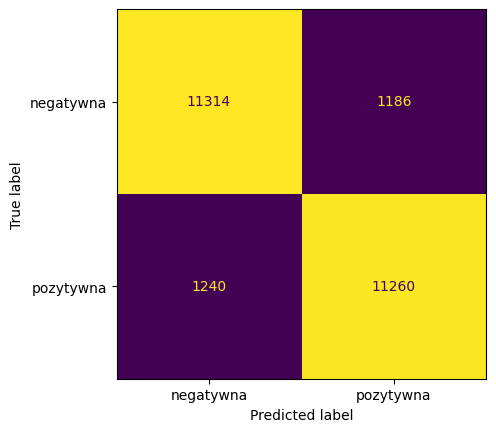

              precision    recall  f1-score   support

   negatywna      0.901     0.905     0.903     12500
   pozytywna      0.905     0.901     0.903     12500

    accuracy                          0.903     25000
   macro avg      0.903     0.903     0.903     25000
weighted avg      0.903     0.903     0.903     25000



In [11]:
# Twoje rozwiązanie

model_koncowy = gs.best_estimator_

y_pred = model_koncowy.predict(X_test)
acc_test = (y_pred == y_test.values).mean()
print(f"accuracy (test): {acc_test:.4f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negatywna", "pozytywna"], colorbar=False)
plt.show()
print(classification_report(y_test, y_pred, target_names=["negatywna", "pozytywna"], digits=3))

In [12]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [13]:
# Twoje rozwiązanie

nazwy_cech = model_koncowy[0].get_feature_names_out()
wagi = pd.Series(model_koncowy[-1].coef_[0], index=nazwy_cech, name="wagi").sort_values()
print("15 najbardziej negatywnych cech:\n", wagi.head(15).round(3), sep="")
print("\n15 najbardziej pozytywnych cech:\n", wagi.tail(15).iloc[::-1].round(3), sep="")
print("\nbigramy wśród 15+15 cech:",
      [w for w in list(wagi.head(15).index) + list(wagi.tail(15).index) if " " in w])


bledy = test_df[y_pred != y_test.values].copy()
bledy["pred"] = y_pred[y_pred != y_test.values]
bledy = bledy[["text", "label", "pred"]]
print(f"\nliczba błędów: {len(bledy)} z {len(test_df)}")
for _, wiersz in bledy.sample(3, random_state=1).iterrows():
    print(f"\n[label: {wiersz['label']}, pred: {wiersz['pred']}]")
    print(wiersz["text"][:500])

print("\n")

moje = [
    "A wonderful film with brilliant acting and a moving story.",
    "Boring, predictable and far too long. I want my two hours back.",
    "This movie was not good.",
    "This movie was not bad at all, I actually enjoyed every minute.",
    "Oh great, another masterpiece where nothing happens for two hours. Truly unforgettable, I fell asleep twice.",
]

for tekst, p in zip(moje, model_koncowy.decision_function(moje)):
    print(f"decision_function = {p:+.2f} → {'pozytywna' if p > 0 else 'negatywna'}   {tekst}")

15 najbardziej negatywnych cech:
worst            -4.187
awful            -3.718
bad              -3.640
boring           -3.461
poor             -3.270
the worst        -3.183
waste            -2.919
disappointment   -2.605
terrible         -2.583
worse            -2.567
poorly           -2.511
disappointing    -2.463
dull             -2.420
unfortunately    -2.396
annoying         -2.333
Name: wagi, dtype: float64

15 najbardziej pozytywnych cech:
great        3.571
excellent    3.237
perfect      2.752
wonderful    2.566
fun          2.286
amazing      2.208
today        2.204
enjoyable    1.965
the best     1.955
brilliant    1.945
superb       1.906
loved        1.876
bit          1.856
favorite     1.854
best         1.835
Name: wagi, dtype: float64

bigramy wśród 15+15 cech: ['the worst', 'the best']

liczba błędów: 2426 z 25000

[label: 1, pred: 0]
"Gypsy" is possibly the greatest musical ever written, so it's too bad that it's film version was such a disappointment. To make up

In [14]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
    Wśród najważniejszych cech są tylko dwa bigramy: `the worst` i `the best`, co oznacza, że model nauczył się głównie zdań/komunikatów emocjonalnych.

2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
    Model mógł się pomylić ponieważ komentarze zawierały komunikaty sprzeczne emocjonalnie, a wystarczy by ktoś odniósł się bardzo negatywnie do np. innej adaptacji, a ten odnośnik będzie istotnie zaważał na ocenie całego komentarza. Człowiek raczej nie mialby wątpliwości bo rozumiałby kontekst, a nie ustalał "emocjonalną średnią ważoną" całego komentarza.


3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
    Model pomylił się raz w ocenie moich recenzji.


4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?
    Granica leży tam, gdzie statystyka małych wycinków i segregacja ilościowa słów (lub par słów) przestaje wystarczać.
    Model musiałby lepiej ogarniać składnię, kontekst i większy zasięg znaczeniowy (nie słowa/n_gramy, a całe zdania), aby poradzić sobie z moimi przykładami.
